In [3]:
from dotenv import load_dotenv
import os, json


load_dotenv(override=True)

openai_key = os.getenv("OPENAI_API_KEY")
openai_default_model = os.getenv("OPENAI_DEFAULT_MODEL", "gpt-6-luna")
gemini_key = os.getenv("GOOGLE_API_KEY")
gemini_default_model = os.getenv("GEMINI_DEFAULT_MODEL", "gemini-4-hydrogen")



# 삼성전자 주가 분석(지난 30일간)

In [8]:
from openai import OpenAI
from pydantic import BaseModel, Field
client = OpenAI()

class TickerRequest(BaseModel):
    name: str = Field(..., description="회사 이름")
    ticker: str = Field(..., description='회사의 thicer 심볼 6자리')

question = '삼성전자 지난 30일간 주가 분석'

res = client.responses.parse(
    model= openai_default_model,
    instructions= '당신은 주식 전문가입니다. 회사 이름이 들어오면 그 회사의 ticker심볼을 알려주세요.',
    input= question,
    text_format= TickerRequest
)

print(res.output_parsed)

name='삼성전자' ticker='005930'


In [9]:
import FinanceDataReader as fdr
from datetime import datetime, timedelta

def get_stock_data(ticker, days):
    end_date= datetime.today()
    start_date= end_date - timedelta(days=days)
    df = fdr.DataReader(ticker, start_date, end_date)
    return df

df = get_stock_data(res.output_parsed.ticker, 30)
print(df)

              Open    High     Low   Close    Volume    Change
Date                                                          
2026-10-26  213500  216000  211500  213500  11376006  0.000000
2026-10-27  222000  225500  220000  225000  14196879  0.053864
2026-10-28  231000  247000  228000  245000  17840544  0.088889
2026-10-29  241000  249000  226000  230500  24975596 -0.059184
2026-10-30  223500  229500  216500  220500  19668075 -0.043384
2026-11-02  219000  232000  217000  230000  14537981  0.043084
2026-11-03  220500  223000  217000  222000  13391670 -0.034783
2026-11-04  226500  228000  208000  221500  22248738 -0.002252
2026-11-05  213000  213500  199800  201500  24657743 -0.090293
2026-11-06  180000  196500  179200  193500  35516270 -0.039702
2026-11-09  187200  195400  183800  187000  19855892 -0.033592
2026-11-10  199400  201500  196400  197300  15289184  0.055080
2026-11-11  197100  208500  196300  208000  16238236  0.054232
2026-11-12  208500  214000  206000  206500  19721557 -0

In [10]:
def analyze_stock(df, days):
    if df.empty:
        return "No data available for the given stock ticker."
    latest_price = df['Close'].iloc[-1]
    highest_price = df['High'].max()
    lowest_price = df['Low'].min()
    average_price = df['Close'].mean()
    analysis = (
        f"최근 {days}일 동안 종가 데이터를 분석한 결과는 다음과 같습니다\n"
        f"Latest Price: {latest_price}\n"
        f"Highest Price in the period: {highest_price}\n"
        f"Lowest Price in the period: {lowest_price}\n"
        f"Average Price in the period: {average_price}"
        f"이 데이터를 기반으로 간단한 분석과 전망을 제공해주세요"
    )
    response = client.responses.create(
        model=openai_default_model,
        instructions= '당신은 주식분석 전문가입니다. 다음 데이터를 기반으로 간단한 분석과 전망을 제공해주세요:\n',
        input=analysis
    )
    return response.output_text
print(analyze_stock(df, 30))

최근 30일 데이터만 보면 **주가는 약세 흐름이며, 현재 가격이 기간 저점에 가까운 상태**입니다.

- **현재가 176,600원**은 평균가 206,995원보다 약 **14.7% 낮습니다**.
- 기간 최고가 249,000원 대비 약 **29.1% 하락**했습니다.
- 기간 저점 174,000원보다는 **약 1.5% 높은 수준**으로, 가격 범위의 하단에 위치합니다.

**전망:** 174,000원 부근이 단기 지지선으로 작용하는지 살펴볼 필요가 있습니다. 이 가격을 지키고 반등하면 평균가 부근인 207,000원대가 첫 저항 구간이 될 수 있습니다. 반대로 저점을 밑돌면 추가 약세 가능성도 있습니다. 다만 30일 요약 통계만으로는 최근 추세나 거래량, 기업 실적을 알 수 없으므로 방향을 단정하기 어렵습니다.


In [11]:
df.head()

,Open,High,Low,Close,Volume,Change
Date,,,,,,
2026-10-26,213500,216000,211500,213500,11376006,0.000000
2026-10-27,222000,225500,220000,225000,14196879,0.053864
2026-10-28,231000,247000,228000,245000,17840544,0.088889
2026-10-29,241000,249000,226000,230500,24975596,-0.059184
2026-10-30,223500,229500,216500,220500,19668075,-0.043384


In [17]:
df.index

DatetimeIndex(['2026-10-26', '2026-10-27', '2026-10-28', '2026-10-29',
               '2026-10-30', '2026-11-02', '2026-11-03', '2026-11-04',
               '2026-11-05', '2026-11-06', '2026-11-09', '2026-11-10',
               '2026-11-11', '2026-11-12', '2026-11-13', '2026-11-16',
               '2026-11-17', '2026-11-18', '2026-11-19', '2026-11-20',
               '2026-11-23'],
              dtype='datetime64[us]', name='Date', freq=None)

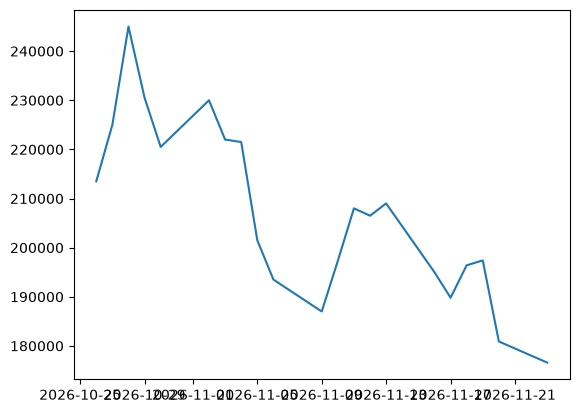

In [16]:
import matplotlib.pyplot as plt
plt.plot(df.index, df['Close'])
plt.show()

# Langchain

In [19]:
from importlib.metadata import version, PackageNotFoundError

packages = ["langchain", "langchain-core", "langgraph", "langchain-openai", "langchain-google-genai"]

for pkg in packages:
    try:
        print(f"{pkg}: {version(pkg)}")
    except PackageNotFoundError:
        print(f"{pkg}: 설치되지 않음")

langchain: 1.5.2
langchain-core: 1.8.4
langgraph: 1.2.24
langchain-openai: 1.8.5
langchain-google-genai: 4.5.2


In [26]:
from langchain_openai import ChatOpenAI
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

# '{서울} 맛집 {3}곳 알려줘

#1. query문 작성 -> prompt 작성 -> template
prompt = ChatPromptTemplate.from_template('{location} 맛집 {count}곳 알려줘')
# print(prompt.invoke({'location':'서울', 'count':3}))

#2. llm을 선언
# llm = ChatOpenAI(model=openai_default_model)
llm = ChatGoogleGenerativeAI(model=gemini_default_model)

#3. Output 처리
output_parser = StrOutputParser()

#4. LCEL (propmt | llm | output)
chain = prompt | llm | output_parser

#5. 실행
res = chain.invoke({'location':'서울', 'count':3})

#6. 결과 출력
print(res)

: 

: 

In [24]:
print(res)

서울에서 유명한 맛집 3곳을 골라봤어요.

1. **우래옥** — 을지로  
   평양냉면과 불고기로 유명해요. 담백한 냉면을 좋아한다면 추천해요.

2. **명동교자** — 명동  
   진한 국물의 칼국수와 만두가 인기예요. 점심시간엔 대기가 길 수 있어요.

3. **토속촌삼계탕** — 경복궁 근처  
   진한 국물의 삼계탕을 맛볼 수 있어요. 경복궁 나들이와 함께 들르기 좋아요.

영업시간이나 휴무일은 방문 전에 확인해 보세요. 원하시면 **한식·데이트·가성비**처럼 취향에 맞춰 다시 추천해 드릴게요.


In [ ]:
from langchain.chat_models import init_chat_model
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate


prompt = ChatPromptTemplate.from_template('{location} 맛집 {count}곳 알려줘')

#2. llm을 선언
llm = init_chat_model(f'openai:{openai_default_model}')
g_llm = init_chat_model(f"google_genai:{gemini_default_model}")

#3. Output 처리
output_parser = StrOutputParser()

#4. LCEL (propmt | llm | output)
o_chain = prompt | llm | output_parser
g_chain = prompt | g_llm | output_parser

#5. 실행
o_res = o_chain.invoke({'location':'서울', 'count':3})
g_res = g_chain.invoke({'location':'서울', 'count':3})

#6. 결과 출력
print(o_res)
print(g_res)


서울에서 유명하고 메뉴가 서로 다른 맛집 3곳을 추천해요.

1. **명동교자** — 명동  
   진한 국물의 칼국수와 만두가 인기예요. 식사 시간에는 대기가 있을 수 있어요.

2. **우래옥** — 을지로  
   평양냉면과 불고기로 잘 알려진 오래된 식당이에요. 냉면은 슴슴한 맛을 좋아한다면 추천해요.

3. **토속촌삼계탕** — 경복궁역 근처  
   진하고 고소한 삼계탕이 대표 메뉴예요. 경복궁이나 서촌을 둘러볼 때 들르기 좋아요.

영업시간과 휴무일은 방문 전에 확인해 보세요.
서울에서 메뉴와 분위기가 겹치지 않으면서도 꾸준히 사랑받는 대표 맛집 3곳을 추천해 드립니다.

---

### 1. 금돼지식당 (중구 신당동 / 약수역)
* **대표 메뉴:** 본삼겹, 눈꽃목살, 등목살, 통돼지 김치찌개
* **특징:** 서울에서 손꼽히는 돼지고기 구이 맛집입니다. 두툼하고 육즙이 풍부한 고기를 직원이 직접 알맞게 구워주어 편하고 맛있게 즐길 수 있습니다.
* **참고:** 대기가 매우 긴 편이므로 방문 전 현장 웨이팅이나 예약 앱(캐치테이블 등) 이용 가능 여부를 확인하시는 것이 좋습니다.

### 2. 우래옥 (중구 주교동 / 을지로4가역)
* **대표 메뉴:** 평양냉면(물냉면), 전통 불고기
* **특징:** 오랜 역사를 지닌 서울의 대표적인 노포입니다. 고기 육향이 진하고 감칠맛이 뚜렷한 육수 덕분에 평양냉면 입문자부터 마니아까지 폭넓게 인기가 많으며, 함께 곁들이는 한우 불고기도 훌륭합니다.
* **참고:** 식사 시간대에는 웨이팅이 긴 편입니다. 방문 전 영업시간과 휴무일(보통 월요일 휴무)을 확인하고 가시는 것을 추천합니다.

### 3. 진미식당 (마포구 공덕동 / 애오개역)
* **대표 메뉴:** 간장게장 정식
* **특징:** 간장게장 단일 메뉴로 유명한 한식 맛집입니다. 너무 짜지 않고 깔끔한 양념에 속이 꽉 찬 게장, 그리고 함께 나오는 감태와 반찬들의 조합이 뛰어납니다.
* **참고:** 인기가 많아 워크인 방문이 어려울 수 있

In [15]:
from langchain.chat_models import init_chat_model
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate

prompt = ChatPromptTemplate.from_template('{area} {location} {count}곳 추천 코스 포함 상세하게 알려줘')


o_llm = init_chat_model(f'openai:{openai_default_model}')
g_llm = init_chat_model(f'google_genai:{gemini_default_model}')

output_parser = StrOutputParser()

o_chain = prompt | o_llm | output_parser
g_chain = prompt | g_llm | output_parser

o_res = o_chain.invoke({'area':'부산', 'location':'관광지', 'count':3})
g_res = g_chain.invoke({'area':'서울', 'location':'고궁', 'count':2})

print(o_res)
print('-' * 100)
print(g_res)

부산을 처음 방문한다면 **감천문화마을 → 자갈치·남포동 일대 → 광안리해수욕장** 순서로 둘러보는 1일 코스를 추천해요. 부산역에서 출발해 서쪽 관광지를 먼저 보고, 저녁에는 바다와 광안대교 야경을 즐기는 동선입니다.

## 추천 코스 한눈에 보기

**부산역 → 감천문화마을 → 자갈치시장·남포동 → 광안리해수욕장**

- 예상 소요: 하루 약 9~10시간
- 이동: 대중교통 기준
- 추천 대상: 부산 첫 방문, 골목 구경과 먹거리, 바다 풍경을 함께 즐기고 싶은 분

---

## 1. 감천문화마을 — 알록달록한 산복도로 골목

**추천 시간: 오전 9:30~12:00**

산비탈을 따라 색색의 집과 골목이 이어지는 부산의 대표적인 풍경 명소예요. 골목 사이로 바다와 마을이 한눈에 들어오고, 작은 공방과 카페도 있어 천천히 둘러보기 좋습니다.

**둘러볼 포인트**
- 마을 전망이 잘 보이는 골목과 포토 스폿
- 골목 곳곳의 벽화와 작은 전시·공방
- 마을 지도를 참고해 주요 포인트를 연결하는 산책

**이동 방법**
- 부산역에서 택시로 약 20~30분
- 대중교통은 도시철도 **토성역**에서 내려 마을버스로 이동하는 방법이 편리합니다. 정류장과 버스 노선은 당일 지도 앱에서 확인하세요.

**참고할 점**
- 언덕과 계단이 많아 편한 신발을 추천해요.
- 실제 주민이 생활하는 공간이므로 조용히 둘러보고, 사유지나 주택 안쪽은 들어가지 않는 것이 좋습니다.
- 걷는 거리가 꽤 있으니 1시간만 잡기보다는 2시간 정도 여유를 두세요.

---

## 2. 자갈치시장·남포동 — 부산 먹거리와 도심 구경

**추천 시간: 12:30~15:30**

감천문화마을에서 이동해 점심을 먹고, 자갈치시장과 남포동 일대를 함께 둘러보세요. 시장 구경, 길거리 음식, 쇼핑을 한 번에 즐길 수 있는 구역입니다.

**추천 동선**
1. 자갈치시장 주변에서 점심 식사
2. 시장 안팎을 둘러보며 부산의 수산물 시장 분위기 체험
3. BIFF광장과 남포동 골목 산책
4. 시간과 체

In [16]:
import inspect
from langchain_core.runnables import Runnable

print('파일 위치', inspect.getfile(Runnable))

print('\n---__or__ 소스코드 ---')
print(inspect.getsource(Runnable.__or__))

파일 위치 c:\workspace1\.venv\Lib\site-packages\langchain_core\runnables\base.py

---__or__ 소스코드 ---
    def __or__(
        self,
        other: Runnable[Output, Other]
        | Callable[[Iterator[Output]], Iterator[Other]]
        | Callable[[AsyncIterator[Output]], AsyncIterator[Other]]
        | Callable[[Output], Other]
        | Mapping[str, Runnable[Output, Any] | Callable[[Output], Any] | Any],
    ) -> RunnableSerializable[Input, Any]:
        """Runnable "or" operator.

        Compose this `Runnable` with another object to create a
        `RunnableSequence`.

        Args:
            other: Another `Runnable` or a `Runnable`-like object.

        Returns:
            A new `Runnable`.

        Raises:
            TypeError: If `other` cannot be coerced to a `Runnable`. This method does
                not return `NotImplemented`, to avoid delegating LCEL composition to
                unrelated reflected `|` implementations. To interoperate, implement
                `Runnabl

In [ ]:
messages = [('system', '당신은 서울의 음식과 문화 전문가입니다.'),
            ('user', '서울틀 대표하는 음식점 3곳 추천해주세요.')]

ret = llm.invoke(messages)

In [17]:
messages = [
    ("system", "당신은 서울의 문화 전문가입니다."),
    ("human", "서울에서 데이트할 때 가 볼 만한 분위기 좋은 곳들을 알려 주세요."),
]

for chunk in llm.stream(messages):
    print(chunk.content, end="", flush=True)

서울은 **동네 산책과 식사를 함께 묶으면** 데이트 코스가 더 자연스러워요. 분위기별로 골라 보세요.

### 1. 고즈넉한 골목 데이트 — 서촌
한옥과 작은 가게, 조용한 골목을 천천히 걷기 좋아요. **통인시장**을 둘러본 뒤 서촌의 식당이나 카페에 들르고, 시간이 남으면 **청운문학도서관**까지 이어 보세요. 북적이는 곳보다 차분한 분위기를 좋아하는 커플에게 잘 어울립니다.

### 2. 전시와 산책 — 삼청동·북촌
**국립현대미술관 서울관**이나 **정독도서관**을 둘러본 다음 삼청동 카페 거리로 이어지는 코스예요. 골목과 한옥 풍경을 함께 즐길 수 있습니다. 북촌은 실제 주민이 생활하는 곳이니 조용히 둘러봐 주세요.

### 3. 트렌디한 저녁 — 성수·서울숲
성수의 편집숍과 카페를 구경하고 **서울숲**을 산책해 보세요. 전시나 팝업을 함께 찾기도 좋고, 저녁 식사 선택지도 다양한 편입니다. 주말에는 인기 가게에 대기 줄이 생길 수 있어요.

### 4. 야경과 로맨틱한 분위기 — 남산
**남산공원**을 걷거나 케이블카를 이용해 **N서울타워** 쪽으로 올라가면 서울 야경을 보기 좋습니다. 날씨가 맑은 날 추천하고, 주말 저녁에는 이동 시간을 넉넉히 잡으세요.

### 5. 강변에서 여유롭게 — 반포한강공원
돗자리나 간단한 간식을 준비해 강바람을 쐬고, 해 질 무렵 산책하기 좋은 곳이에요. 계절이나 날씨에 따라 즐길 거리가 달라지니 방문 전에 공원 시설과 행사 운영 여부를 확인하면 좋습니다.

### 6. 오래된 서울의 밤 — 을지로
낡은 건물 사이의 작은 식당과 바를 찾아다니는 재미가 있어요. 번쩍이는 분위기보다는 아늑하고 개성 있는 저녁을 원할 때 추천합니다. 골목이 복잡한 편이라 마음에 드는 곳은 미리 예약하거나 위치를 확인해 두세요.

### 7. 이색적인 골목 데이트 — 익선동
한옥 골목에 카페와 식당이 모여 있어 짧게 둘러보기 좋습니다. 다만 골목이 좁고 주말에는 꽤 붐비므로, 조금 한적한 시간을 원한다면 평일 낮이나 이른 저녁이 좋아요

In [ ]:
batch_messages = [
    [("system", "당신은 서울의 음식 전문가입니다."), ("human", "서울 광장시장에서 먹을 만한 길거리 음식들을 소개해 주세요.")],
    [("system", "당신은 서울의 문화 전문가입니다."), ("human", "서울에서 데이트할 때 가 볼 만한 분위기 좋은 곳들을 알려 주세요.")],
]

responses = llm.batch(batch_messages, config={"max_concurrency": 5})   # 동시 실행 수 제한
for r in responses:
    print(r.content)
    print("-" * 50)

In [18]:
import asyncio, time

question1 = [("system", "당신은 서울의 음식 전문가입니다."), ("human", "광장시장 대표 음식 한 가지를 한 문장으로 알려 주세요.")]
question2 = [("system", "당신은 서울의 음식 전문가입니다."), ("human", "남대문시장 대표 음식 한 가지를 한 문장으로 알려 주세요.")]
question3 = [("system", "당신은 서울의 음식 전문가입니다."), ("human", "동대문시장 대표 음식 한 가지를 한 문장으로 알려 주세요.")]

In [19]:
%%time
result1 = llm.invoke(question1)
result2 = llm.invoke(question2)
result3 = llm.invoke(question3)

CPU times: total: 0 ns
Wall time: 6.64 s


In [23]:
import asyncio

results = await asyncio.gather(
        llm.ainvoke(question1),
        llm.ainvoke(question2),
        llm.ainvoke(question3),
    )
for r in results:
    print(r.content)


광장시장의 대표 음식은 고소하고 바삭한 녹두빈대떡입니다.
남대문시장의 대표 음식은 매콤하고 진한 양념에 졸여 낸 갈치조림입니다.
동대문시장의 대표 음식은 진한 닭 육수에 떡과 감자를 넣어 끓여 먹는 닭한마리입니다.


In [25]:
conversation = [
    ('system', "당신은 여행을 추천해 주는 전문 AI입니다.")
]

while True:
    user_input = input("User: ")
    if user_input.lower() in ['exit', 'quit', '종료']:
        print("대화를 종료합니다.")
        break
    
    conversation.append(('user', user_input))
    
    ai_msg = llm.invoke(conversation)
    print(f"AI: {ai_msg.content}\n")
    
    conversation.append(('assistant', ai_msg.content))

AI: 딱 한 곳만 고른다면 **광안리해수욕장**을 추천해요. 탁 트인 바다와 광안대교를 함께 볼 수 있고, 해 질 무렵부터 밤까지 풍경이 특히 아름답습니다. 해변을 걷고 근처 카페나 식당에 들르면 부산의 바다와 분위기를 한곳에서 즐길 수 있어요.

AI: 가장 편하고 쉬운 방법은 **지하철**이에요.

1. 부산역에서 **1호선 노포 방면**을 타고 **서면역**으로 이동합니다.
2. 서면역에서 **2호선 장산 방면**으로 환승해 **광안역**에서 내립니다.
3. 역에서 광안리해수욕장까지 표지판을 따라 걸으면 약 **10~15분** 걸려요.

전체 이동은 환승 대기와 도보를 포함해 대략 **40~50분** 정도 예상하면 됩니다. 짐이 많거나 일행이 있다면 택시로는 교통 상황에 따라 약 **25~35분** 걸릴 수 있어요.

AI: 광안리해수욕장 근처라면 이런 곳들을 추천해요.

- **수변최고돼지국밥** — 부산식 돼지국밥과 수육을 맛보고 싶을 때 좋아요. 민락동 쪽에 있어 해변 동쪽에서 가기 편합니다.
- **민락회센터·민락어민활어직판장** — 회를 먹고 싶다면 여러 횟집을 비교해 고를 수 있어요. 보통 회를 포장하거나 상차림 식당에서 먹는 방식입니다.
- **언양불고기 부산집** — 달콤한 양념의 불고기를 즐기기 좋은 곳으로, 광안리 해변 남쪽 남천동 방향에 있어요.
- **다리집** — 부산식 떡볶이와 튀김으로 유명한 분식집이에요. 가볍게 먹거나 간식으로 들르기 좋습니다.

인기 있는 곳은 대기할 수 있고 영업시간·휴무가 바뀔 수 있으니, 방문 전에 지도 앱에서 최신 정보를 확인해 주세요.

AI: 원하시는 음식 종류나 예산대가 있으면 알려주세요. 광안리 근처에서 취향에 맞춰 더 좁혀 추천해 드릴게요.



KeyboardInterrupt: Interrupted by user

In [26]:
import gradio as gr

def content_to_text(content):
    """Gradio 메시지의 content(문자열 또는 블록 리스트)를 텍스트로 변환"""
    if isinstance(content, str):
        return content
    if isinstance(content, list):
        return " ".join(c.get("text", "") for c in content if isinstance(c, dict))
    return str(content)

def history_to_openai(history):
    """Gradio history → OpenAI Responses API input 형식 (role, content만 남김)"""
    return [{"role": m["role"], "content": content_to_text(m["content"])}
            for m in history if m.get("role") in ("user", "assistant")]

# API 없이 동작 확인: Gradio 6 Chatbot이 실제로 넘겨주는 형식으로 테스트
sample = gr.Chatbot().preprocess(gr.Chatbot().postprocess(
    [{"role": "user", "content": "안녕"}, {"role": "assistant", "content": "반가워요"}]))
print("Gradio가 넘겨주는 형식 :", sample[0])
print("OpenAI용으로 변환      :", history_to_openai(sample))


from openai import OpenAI
client = OpenAI()

def chat_fn(message, history):
    input_items = history_to_openai(history) + [{"role": "user", "content": message}]
    answer = ""
    with client.responses.stream(
        model=openai_default_model,
        instructions="당신은 친절한 AI 챗봇입니다. 한국어로 간결하게 답하세요.",
        input=input_items,
        reasoning={"effort": "low"},
        max_output_tokens=1000,
    ) as stream:
        for event in stream:
            if event.type == "response.output_text.delta":
                answer += event.delta
                yield answer                 # 지금까지의 답변 전체를 yield

demo = gr.ChatInterface(
    fn=chat_fn,
    title="OpenAI 챗봇",
    examples=["파이썬 리스트가 뭐야?", "Gradio를 한 문장으로 설명해 줘"],
)
demo.launch()

c:\workspace1\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Gradio가 넘겨주는 형식 : {'role': 'user', 'metadata': None, 'content': [{'text': '안녕', 'type': 'text'}], 'options': None}
OpenAI용으로 변환      : [{'role': 'user', 'content': '안녕'}, {'role': 'assistant', 'content': '반가워요'}]
* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


# 실습하기

In [ ]:
query = [('system', '너는 친절한 챗봇이야 답변은 간단히 3문장으로 대답해줘'),
         ('user', '{question}')]
prompt = ChatPromptTemplate.from_messages(query)

chain = prompt | llm
ret = chain.invoke({'question': '서울 맛집 3곳 알려줘'})
print(ret.content)

1. 광장시장 ‘박가네빈대떡’은 바삭한 빈대떡과 시장 분위기를 즐기기 좋아요.
2. 을지로 ‘을지면옥’은 깔끔한 평양냉면으로 유명해요.
3. 신당동 ‘마복림떡볶이’는 매콤달콤한 즉석떡볶이를 맛볼 수 있어요.


In [ ]:
from langchain_core.prompts import 

query = [('system', '너는 친절한 챗봇이야 답변은 간단히 3문장으로 대답해줘'),
         ('user', '{question}')]
prompt = ChatPromptTemplate.from_messages(query)

chain = prompt | llm
ret = chain.invoke({'question': '서울 맛집 3곳 알려줘'})
print(ret.content)